# Metastatic Breast Cancer 2013–2016 (DFCI, Garrido-Castro et al., CCR 2020) — exploratory, no deck questions

This study is on slide 3 of Jacob's deck but has no questions attached. The cells below profile the dataset and run the
breast-cancer questions from the BPC BrCa notebook (Br1, Br3) on it as an **independent replication cohort**, so Jacob can decide
whether it is worth keeping.

Data: `mbc_genie_2020` from genie.cbioportal.org. 856 patients, one sample each (OncoPanel v1/v2), **OS from metastatic diagnosis**
(`OS_MONTHS`, the attribute the portal's KM plot uses) and from initial diagnosis, subtype at initial and metastatic diagnosis, sample
type and site, timing of the biopsy relative to first-line systemic therapy, and adjuvant-therapy flags. No regimen table and no
sequencing date, so no left truncation is possible.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "dfci_mbc"
F = []

P = cb.Portal("mbc_genie_2020")
log = pd.read_csv(cb.DATA / "genie_portal" / "download_log.csv")
display(log[log.study_id == "mbc_genie_2020"])

,study_id,file,rows,md5
15,mbc_genie_2020,clinical_attributes.tsv,29,f7bd9e2063a692b738a254f8e8466d83
16,mbc_genie_2020,data_clinical_patient.tsv,856,5d234955782f1af643f7de91b75d4211
17,mbc_genie_2020,data_clinical_sample.tsv,856,4720f90a0bb73856039b57596f7acb43
18,mbc_genie_2020,data_timeline.tsv,0,68b329da9893e34099c7d8ad5cb9c940
19,mbc_genie_2020,data_cna.tsv,424576,08340a1800643267660f3bef767ebd4a
20,mbc_genie_2020,data_mutations.tsv,5629,b503817f5c2acab9babbfe67119d7c0f
21,mbc_genie_2020,gene_panel_per_sample.tsv,856,99d6103a8e33d4779241221ba0b1129c


## Cohort

patients 856, deaths 271, median OS from met dx 63.7 mo; alteration matrix 856 x 551; unknown panel 0


sample_type,Local Recurrence,Metastatic Recurrence,Primary,Unspecified,All
subtype,,,,,
HER2+/HR+,0,29,39,0,68
HER2+/HR-,0,24,31,0,55
HER2-/HR+,5,157,273,8,443
TNBC,4,50,94,2,150
Unknown,2,29,107,2,140
All,11,289,544,12,856


biopsy_timing
not stated         664
Treatment naive    146
gt 30               38
le 30                8
Name: biopsy timing vs first-line therapy, dtype: int64

PosixPath('/Users/daniel/Code/explore-genie/results/dfci_mbc/cohort_gene_frequency')

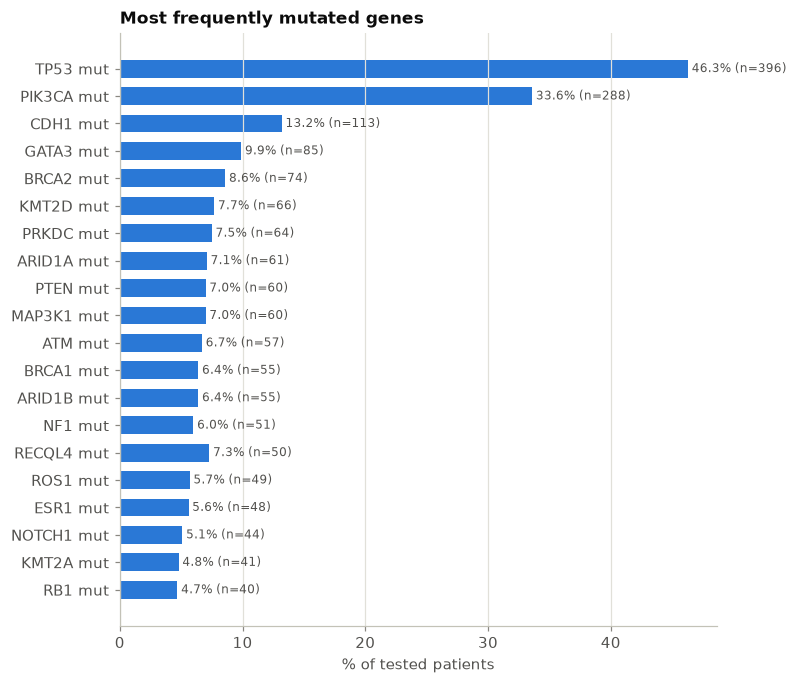

In [2]:
S = P.survival()                                  # time = OS months from metastatic diagnosis
S["time_init"] = pd.to_numeric(S.OS_MONTHS_INIT_DIAGNOSIS, errors="coerce")
S["subtype"] = S.SUBTYPE_METS.fillna("Unknown")
S["age_met"] = pd.to_numeric(S.AGE, errors="coerce")
S["dfi"] = pd.to_numeric(S.DFI_MONTHS, errors="coerce")
sm = P.samples
S["sample_type"] = sm.SAMPLE_TYPE.reindex(S.index)
S["biopsy_timing"] = S["1ST_LINE_TO_BIOPSY_<=_30"].fillna("not stated")
A = P.alterations()
print(f"patients {len(S)}, deaths {int(S.event.sum())}, median OS from met dx {cb.km_table(S.assign(g='all'), 'g').median_months[0]} mo; "
      f"alteration matrix {len(A.patients)} x {len(A.genes)}; unknown panel {A.n_unknown_panel}")
display(pd.crosstab(S.subtype, S.sample_type, margins=True))
display(S.biopsy_timing.value_counts().rename("biopsy timing vs first-line therapy"))
freq = A.frequency(kinds=("mut", "amp", "homdel"))
ax = cb.bar_freq(freq[freq.kind == "mut"], top=20, title="Most frequently mutated genes")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")

## OS from metastatic diagnosis by subtype (context for everything below)

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,HER2-/HR+,443,116,78.6,0.937,0.857,0.591,6.5e-26
1,HER2+/HR+,68,13,inf,0.949,0.886,0.728,6.5e-26
2,HER2+/HR-,55,12,183,0.961,0.891,0.787,6.5e-26
3,TNBC,150,79,18.9,0.729,0.428,0.171,6.5e-26
4,Unknown,140,51,45.6,0.839,0.689,0.422,6.5e-26


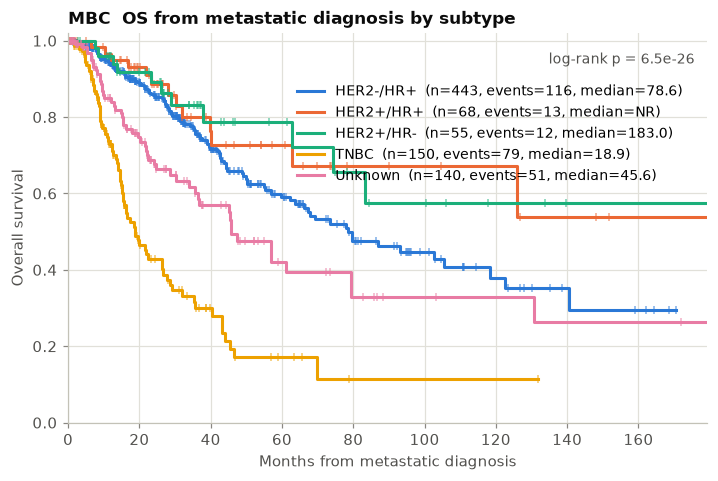

In [3]:
order = ["HER2-/HR+", "HER2+/HR+", "HER2+/HR-", "TNBC", "Unknown"]
ax, t0 = cb.km_plot(S, "subtype", order=order, title="MBC  OS from metastatic diagnosis by subtype", xlabel="Months from metastatic diagnosis", risk_table=False)
cb.save(DS, "M0", table=t0, fig=ax.figure, slug="os_by_subtype")
display(t0)

## M1 — Br1 replicated here: PIK3CA-only vs TP53-only, OS from metastatic diagnosis

subtype,HER2+/HR+,HER2+/HR-,HER2-/HR+,TNBC,Unknown,All
profile,,,,,,
PIK3CA only,12,5,131,0,31,179
TP53 only,20,26,77,115,49,287
both,17,19,47,15,11,109
neither,19,5,188,20,49,281
All,68,55,443,150,140,856


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_tp53_vs_pik3ca,HR_adj_subtype_age,p_adj
0,PIK3CA only,179,42,106,0.956,0.901,0.622,1.48e-10,3.01,2.87,4.78e-07
1,TP53 only,287,123,30.3,0.795,0.576,0.336,1.48e-10,3.01,2.87,4.78e-07


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_tp53_vs_pik3ca
0,PIK3CA only,131,33,87,0.957,0.892,0.583,7.25e-05,2.62
1,TP53 only,77,32,37.7,0.859,0.661,0.354,7.25e-05,2.62


[M1] consistent with BPC BrCa Br1: PIK3CA-only n=179 median 105.5 vs TP53-only n=287 median 30.3 mo from met dx, p=1.5e-10, HR 3.01, subtype/age-adjusted 2.87 (p=4.8e-07); within HR+/HER2−: median 87.0 vs 37.7 mo, HR 2.62 (p=7.2e-05).


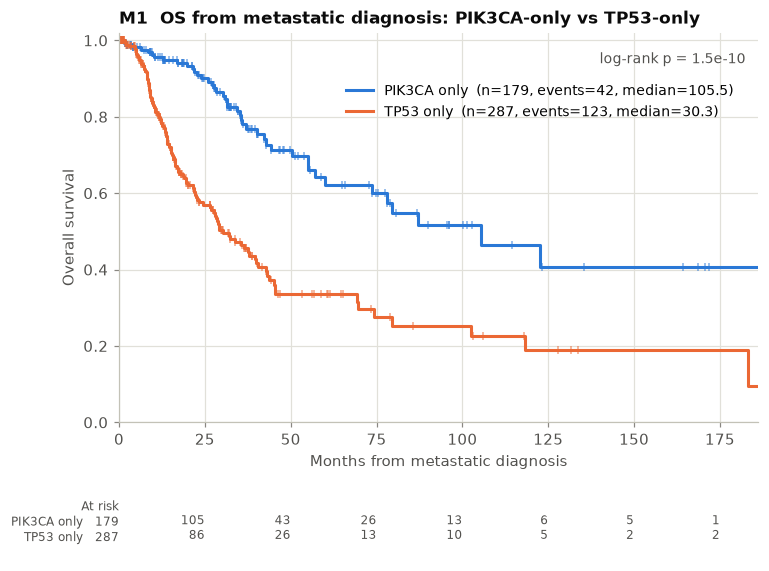

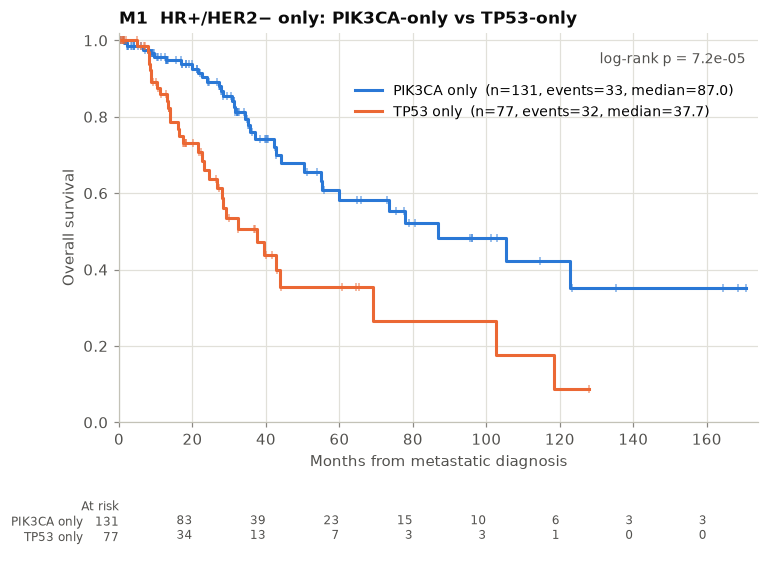

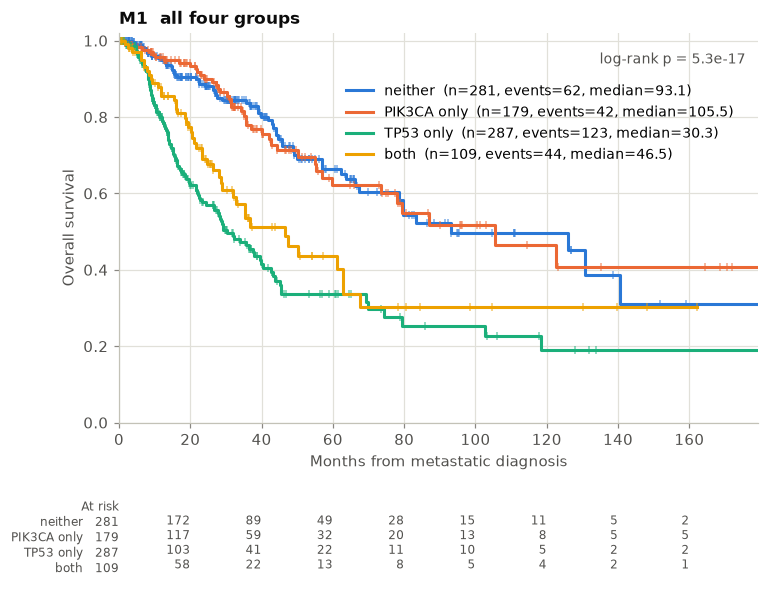

In [4]:
grp = A.combo_groups(["PIK3CA", "TP53"], min_n=1, wt_label="neither").replace({"PIK3CA": "PIK3CA only", "TP53": "TP53 only", "PIK3CA+TP53": "both"})
d1 = S.join(grp, how="inner")
order4 = ["neither", "PIK3CA only", "TP53 only", "both"]
display(pd.crosstab(d1.profile, d1.subtype, margins=True))
d1x = d1[d1.profile.isin(["PIK3CA only", "TP53 only"])]
ax, t1 = cb.km_plot(d1x, "profile", order=["PIK3CA only", "TP53 only"], title="M1  OS from metastatic diagnosis: PIK3CA-only vs TP53-only", xlabel="Months from metastatic diagnosis")
h1 = cb.hr(d1x.assign(feat=(d1x.profile == "TP53 only")), "feat")
h1s = cb.hr(d1x.assign(feat=(d1x.profile == "TP53 only")), "feat", adjust=["subtype", "age_met"])
t1["HR_tp53_vs_pik3ca"] = h1["HR"]; t1["HR_adj_subtype_age"] = h1s["HR"]; t1["p_adj"] = h1s["p_cox"]
cb.save(DS, "M1", table=t1, fig=ax.figure, slug="pik3ca_only_vs_tp53_only")
display(t1)
hrp = d1x[d1x.subtype == "HER2-/HR+"]
ax, t1b = cb.km_plot(hrp, "profile", order=["PIK3CA only", "TP53 only"], title="M1  HR+/HER2− only: PIK3CA-only vs TP53-only", xlabel="Months from metastatic diagnosis")
h1b = cb.hr(hrp.assign(feat=(hrp.profile == "TP53 only")), "feat")
t1b["HR_tp53_vs_pik3ca"] = h1b["HR"]
cb.save(DS, "M1", table=t1b, fig=ax.figure, slug="hrpos_her2neg_only")
display(t1b)
ax, t1c = cb.km_plot(d1, "profile", order=order4, title="M1  all four groups", xlabel="Months from metastatic diagnosis")
cb.save(DS, "M1", table=t1c, fig=ax.figure, slug="four_groups")
cb.finding("M1", "consistent with BPC BrCa Br1" if t1.p_logrank[0] < 0.05 else "not reproduced",
           f"PIK3CA-only n={t1.n[0]} median {t1.median_months[0]} vs TP53-only n={t1.n[1]} median {t1.median_months[1]} mo from met dx, p={cb.fmt_p(t1.p_logrank[0])}, "
           f"HR {h1['HR']:.2f}, subtype/age-adjusted {h1s['HR']:.2f} (p={cb.fmt_p(h1s['p_cox'])}); within HR+/HER2−: median {t1b.median_months[0]} vs {t1b.median_months[1]} mo, HR {h1b['HR']:.2f} (p={cb.fmt_p(t1b.p_logrank[0])}).", F)

## M2 — Gene screen vs OS from metastatic diagnosis (all patients, subtype-adjusted HR), and within PIK3CA-mutant patients (Br3 analogue)

,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,TP53 mut,TP53,mut,396,460,167,104,35.4,106,1.63e-17,2.58,1.95,3.41,3.08e-11,856,3.2e-15
1,NOTCH2 amp,NOTCH2,amp,11,845,7,264,20,67.3,4.33e-05,1.53,0.702,3.32,0.285,856,0.00425
2,ERBB2 amp,ERBB2,amp,116,740,23,248,126,55.2,0.00012,0.575,0.319,1.04,0.066,856,0.00783
3,IKZF3 amp,IKZF3,amp,106,750,22,249,126,56.8,0.000186,0.59,0.331,1.05,0.0748,856,0.0091
4,RB1 mut,RB1,mut,40,816,21,250,29.2,67.7,0.000257,2.24,1.43,3.51,0.000447,856,0.0101
5,GATA3 mut,GATA3,mut,85,771,19,252,126,62.2,0.00883,0.726,0.45,1.17,0.189,856,0.275
6,CDKN2A homdel,CDKN2A,homdel,24,832,14,257,26.3,66.3,0.00982,1.09,0.626,1.9,0.759,856,0.275
7,MYC amp,MYC,amp,47,809,22,249,28.2,67.7,0.0165,1.35,0.862,2.11,0.191,856,0.398
8,ATM mut,ATM,mut,57,799,13,258,118,62.9,0.0183,0.537,0.307,0.94,0.0296,856,0.398
9,RAD21 amp,RAD21,amp,33,823,18,253,35.1,67.7,0.023,1.65,1.02,2.67,0.0424,856,0.45


,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,EXT1 amp,EXT1,amp,10,278,8,78,16,78,6.66e-06,4.46,2.12,9.38,7.98e-05,288,0.000282
1,RAD21 amp,RAD21,amp,12,276,10,76,18.6,78,1.08e-05,4.1,2.09,8.04,4.17e-05,288,0.000282
2,TP53 mut,TP53,mut,109,179,44,42,46.5,106,0.000115,2.65,1.65,4.26,5.25e-05,288,0.00199
3,MYC amp,MYC,amp,12,276,9,77,28.2,78,0.000299,2.4,1.13,5.07,0.0219,288,0.00389
4,MEN1 mut,MEN1,mut,10,278,5,81,16.9,73.5,0.00039,6.02,2.32,15.6,0.000228,288,0.00405
5,ERBB2 amp,ERBB2,amp,41,247,6,80,inf,61.2,0.0188,0.484,0.17,1.38,0.174,288,0.163
6,IKZF3 amp,IKZF3,amp,39,249,6,80,inf,61.2,0.0224,0.504,0.177,1.44,0.199,288,0.166
7,KDM6A mut,KDM6A,mut,11,277,5,81,35.1,73.5,0.0416,2.86,1.12,7.27,0.0278,288,0.262
8,FGFR1 amp,FGFR1,amp,16,272,5,81,61.2,78,0.0454,2.1,0.833,5.29,0.116,288,0.262
9,MAP3K1 mut,MAP3K1,mut,33,255,9,77,inf,62.8,0.0558,0.52,0.256,1.06,0.0705,288,0.29


[M2] signal: All MBC, FDR<0.1: TP53 mut HR 2.58 q=3.2e-15, NOTCH2 amp HR 1.53 q=0.0042, ERBB2 amp HR 0.57 q=0.0078, IKZF3 amp HR 0.59 q=0.0091, RB1 mut HR 2.24 q=0.01. Within PIK3CA-mut, FDR<0.1: EXT1 amp HR 4.46 q=0.00028, RAD21 amp HR 4.10 q=0.00028, TP53 mut HR 2.65 q=0.002, MYC amp HR 2.40 q=0.0039, MEN1 mut HR 6.02 q=0.0041.


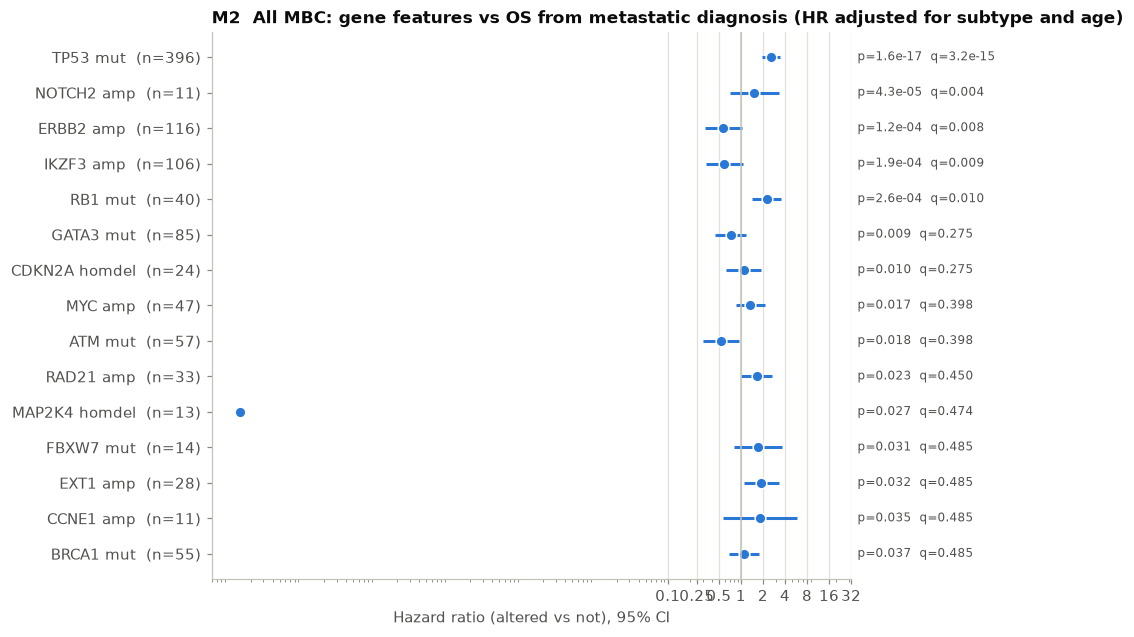

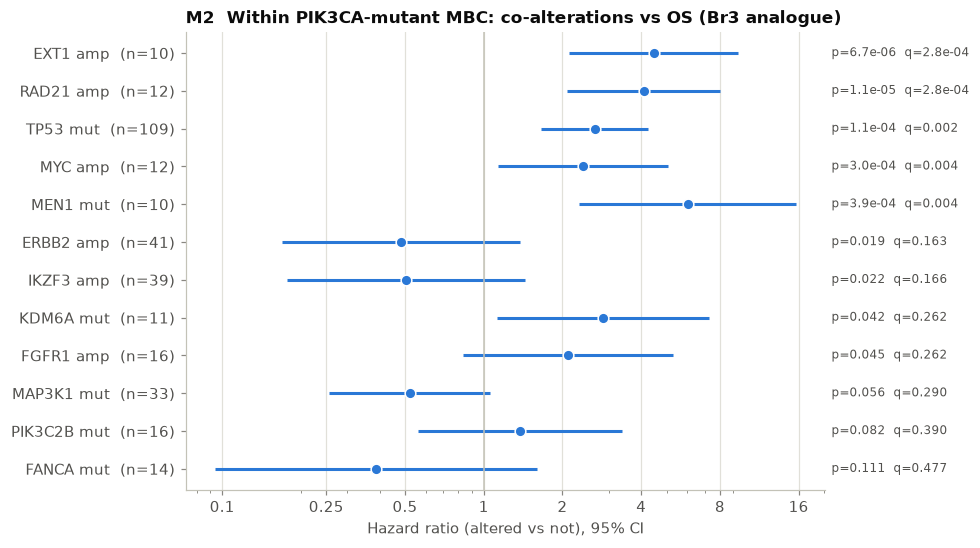

In [5]:
scr = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel"), min_n=10, adjust=["subtype", "age_met"])
ax = cb.forest_plot(scr, top=15, title="M2  All MBC: gene features vs OS from metastatic diagnosis (HR adjusted for subtype and age)")
cb.save(DS, "M2", table=scr, fig=ax.figure, slug="gene_screen_all")
display(scr.head(15))
pik_ids = A.status("PIK3CA").pipe(lambda s: s.index[s])
scr3 = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel"), min_n=10, patients=pik_ids, adjust=["subtype", "age_met"])
scr3 = scr3[scr3.gene != "PIK3CA"].reset_index(drop=True)
ax = cb.forest_plot(scr3, top=12, title="M2  Within PIK3CA-mutant MBC: co-alterations vs OS (Br3 analogue)")
cb.save(DS, "M2", table=scr3, fig=ax.figure, slug="gene_screen_in_pik3ca")
display(scr3.head(12))
hits = scr[scr.q_bh < 0.1]; hits3 = scr3[scr3.q_bh < 0.1]
cb.finding("M2", "signal" if (len(hits) or len(hits3)) else "no signal",
           "All MBC, FDR<0.1: " + (", ".join(f"{r.feature} HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits.itertuples()) or "none") +
           ". Within PIK3CA-mut, FDR<0.1: " + (", ".join(f"{r.feature} HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits3.itertuples()) or "none") + ".", F)

## M3 — Biopsy timing and acquired alterations: treatment-naive vs after first-line therapy
The study records whether the sequenced sample was taken before any first-line systemic therapy or after it. ESR1 mutations are the classic therapy-acquired alteration in HR+ disease; this is the sanity check for using this study for pre/post comparisons (cf. CRC questions C2/C3).

In [6]:
hrpos = S[S.subtype == "HER2-/HR+"]
timing = hrpos.biopsy_timing.replace({"gt 30": "> 30 days after first-line start", "le 30": "<= 30 days after first-line start", "Treatment naive": "treatment naive"})
anchor = (timing[timing != "not stated"] != "treatment naive")
co = A.cooccurrence(anchor, kinds=("mut", "amp", "homdel"), min_n=5)
co = co.rename(columns={"n_anchor": "n_post_treatment", "altered_in_anchor": "altered_post", "pct_in_anchor": "pct_post", "n_rest": "n_naive", "altered_in_rest": "altered_naive", "pct_in_rest": "pct_naive"}).sort_values("p_fisher")
cb.save(DS, "M3", table=co, slug="post_vs_naive_hrpos")
display(timing.value_counts())
display(co.head(12))
esr1 = co[co.gene == "ESR1"]
cb.finding("M3", "descriptive",
           f"HR+/HER2− with stated timing: {int(anchor.sum())} post-first-line vs {int((~anchor).sum())} treatment-naive samples. " +
           (f"ESR1 mut {esr1.pct_post.iloc[0]}% post vs {esr1.pct_naive.iloc[0]}% naive (Fisher p={cb.fmt_p(esr1.p_fisher.iloc[0])}). " if len(esr1) else "") +
           "Top differences: " + ", ".join(f"{r.gene} {r.kind} {r.pct_post}% vs {r.pct_naive}%" for r in co.head(3).itertuples()) + ".", F)

biopsy_timing
not stated                           320
treatment naive                       90
> 30 days after first-line start      28
<= 30 days after first-line start      5
Name: count, dtype: int64

,gene,kind,n_post_treatment,altered_post,pct_post,n_naive,altered_naive,pct_naive,p_fisher,q_bh
1,ESR1,mut,33,9,27.3,90,5,5.6,0.00203,0.0604
3,PRKDC,mut,33,8,24.2,90,4,4.4,0.00281,0.0604
6,ATM,mut,33,5,15.2,90,1,1.1,0.00529,0.0758
9,CIITA,mut,33,4,12.1,90,1,1.1,0.0181,0.195
40,KMT2D,mut,33,0,0,90,12,13.3,0.0349,0.3
8,CDH1,mut,33,4,12.1,90,24,26.7,0.0967,0.57
39,SETD2,mut,33,0,0,90,8,8.9,0.107,0.57
18,DMD,mut,33,3,9.1,90,2,2.2,0.119,0.57
13,MTOR,mut,33,3,9.1,90,2,2.2,0.119,0.57
38,NOTCH1,mut,33,0,0,90,7,7.8,0.188,0.657


[M3] descriptive: HR+/HER2− with stated timing: 33 post-first-line vs 90 treatment-naive samples. ESR1 mut 27.3% post vs 5.6% naive (Fisher p=0.002). Top differences: ESR1 mut 27.3% vs 5.6%, PRKDC mut 24.2% vs 4.4%, ATM mut 15.2% vs 1.1%.


## Summary of findings

In [7]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,M1,consistent with BPC BrCa Br1,"PIK3CA-only n=179 median 105.5 vs TP53-only n=287 median 30.3 mo from met dx, p=1.5e-10, HR 3.01, subtype/age-adjusted 2.87 (p=4.8e-07); within HR+/HER2−: median 87.0 vs 37.7 mo, HR 2.62 (p=7.2e-05)."
1,M2,signal,"All MBC, FDR<0.1: TP53 mut HR 2.58 q=3.2e-15, NOTCH2 amp HR 1.53 q=0.0042, ERBB2 amp HR 0.57 q=0.0078, IKZF3 amp HR 0.59 q=0.0091, RB1 mut HR 2.24 q=0.01. Within PIK3CA-mut, FDR<0.1: EXT1 amp HR 4.46 q=0.00028, RAD21 amp HR 4.10 q=0.00028, TP53 mut HR 2.65 q=0.002, MYC amp HR 2.40 q=0.0039, MEN1 mut HR 6.02 q=0.0041."
2,M3,descriptive,"HR+/HER2− with stated timing: 33 post-first-line vs 90 treatment-naive samples. ESR1 mut 27.3% post vs 5.6% naive (Fisher p=0.002). Top differences: ESR1 mut 27.3% vs 5.6%, PRKDC mut 24.2% vs 4.4%, ATM mut 15.2% vs 1.1%."
